# MK Praktikum Unggulan Universitas Gunadarma
# Nama Mata Kuliah: Praktikum Komputasi Big Data (Tingkat 2)  
---
# Pertemuan IV
Pada praktikum ini, Anda akan melihat beberapa contoh Exploratory Data Analysis (EDA) pada data set pembuatan semen (Cement Manufacturing).

* [Pengambilan Data](#1)
* [Univariate analysis](#2)
* [Bivariate analysis](#3)

### Overview Dataset
"Data Pembuatan Semen (Cement Manufacturing)"

Beton merupakan material terpenting dalam teknik sipil. Kuat tekan beton adalah fungsi yang sangat nonlinier dari umur dan bahan. Bahan-bahan tersebut antara lain semen, terak tanur tinggi, fly ash, air, superplasticizer, agregat kasar, dan agregat halus. Dataset ini berisi data mengenai kekuatan semen, bahan penyusun dan waktu campuran.

Kekuatan tekan beton (MPa) untuk campuran tertentu di bawah umur tertentu (hari) ditentukan dari informasi laboratorium. Data ini merupakan data (tidak diskalakan). Data memiliki 8 variabel input kuantitatif, dan 1 variabel output kuantitatif, dan 1030 kejadian (pengamatan).

<br>Data set ini berisikan beberapa kategori sebagai berikut:
* cement (kg)
* slag (blast furnace slag, kg)
* ash (fly ash, kg)
* water (kg)
* superplastic (superplasticizer, kg)
* coarseagg (coarse aggregate, kg)
* fineagg (fine aggregate, kg)
* age (days, 1-365)
* strength (Concrete compressive strength, MPa)

<a id="1"></a>

# 1. Pengambilan Data:

## 1.1 Import packages

In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.stats import ttest_ind, ttest_rel
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

## 1.2 Import data

In [9]:
data = pd.read_csv("https://raw.githubusercontent.com/supasonicx/ATA-praktikum-01/main/concrete.csv")
data.head(10)

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,141.3,212.0,0.0,203.5,0.0,971.8,748.5,28,29.89
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51
2,250.0,0.0,95.7,187.4,5.5,956.9,861.2,28,29.22
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
4,154.8,183.4,0.0,193.3,9.1,1047.4,696.7,28,18.29
5,255.0,0.0,0.0,192.0,0.0,889.8,945.0,90,21.86
6,166.8,250.2,0.0,203.5,0.0,975.6,692.6,7,15.75
7,251.4,0.0,118.3,188.5,6.4,1028.4,757.7,56,36.64
8,296.0,0.0,0.0,192.0,0.0,1085.0,765.0,28,21.65
9,155.0,184.0,143.0,194.0,9.0,880.0,699.0,28,28.99


<div style="text-align: center;">
  <h1>Instruksi Tugas Praktikum FIKTI, FTI, FTSP, FK dan FIKF</h1>

### Instruksi Praktikum:
1. Buat <b>univariate analysis</b> pada kolom <code>'cement'</code>.
2. Buat <b>bivariate analysis</b> untuk kolom <code>'cement'</code> dan <code>'strength'</code>.
2. Jelaskan kesimpulan yang bisa di ambil dari analysis yang Anda lakukan.


<div class="alert alert-info">
    <strong>Catatan!</strong><br>
    Pada bagian <code>#CODE HERE <...></code> ganti dengan code python sesuai dengan perintah. <br>
    Pada bagian <code>#Ketik disini...</code> cukup ketik jawaban atas pertanyaan yang diberikan menggunakan Bahasa Indonesia. <br><br>
    <b>Silakan simak Video Penjelasan Materi Hands-on pada Pertemuan sebelumnya sebagai bahan acuan. </b>
    </div>

# Univariate Analysis
<a id="2"></a>

- Univariate analysis adalah jenis analisis statistik yang melibatkan satu variabel pada suatu waktu.
- Tujuannya adalah untuk memberikan gambaran tentang distribusi, statistik deskriptif, dan sifat-sifat lainnya dari variabel tunggal.
- Contoh univariate analysis termasuk histogram, box plot, ringkasan statistik seperti mean, median, dan modus, serta perhitungan frekuensi.

## Kolom "cement"

### **i.	Distribusi Histogram**

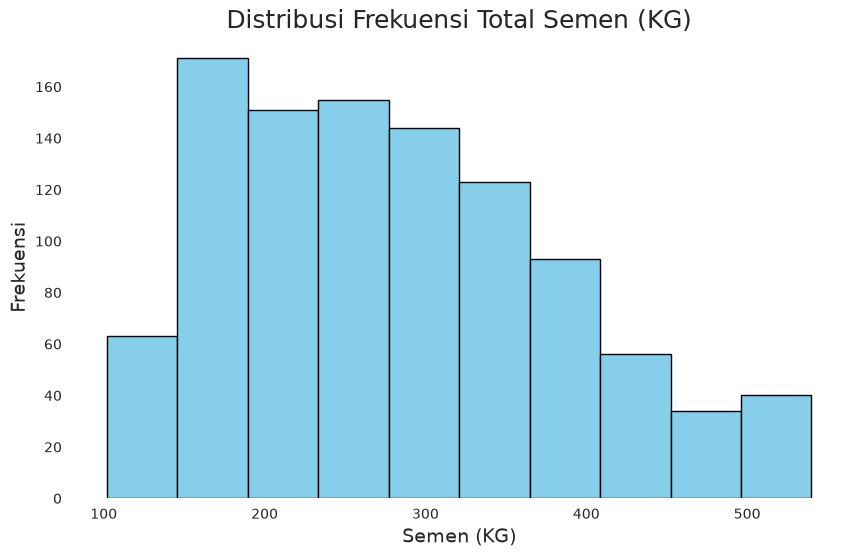

In [10]:
# Buat visualiasi histogram pada kolom "cement"
sns.set({'figure.figsize': (10, 6)}, rc={'axes.facecolor': 'white'})
plt.hist(data['cement'], bins=10, color='skyblue', edgecolor='black')
plt.title('Distribusi Frekuensi Total Semen (KG)', size=18)
plt.xlabel('Semen (KG)', size=14)
plt.ylabel('Frekuensi', size=14)
plt.show()

### **ii.	Deskripsi**

# Jelaskan hasil visualiasi histogram tersebut
Deskripsi histogram kolom 'cement':
1. Histogram dibentuk dari 1030 pengamatan dengan rentang nilai sekitar 102 kg sampai 540 kg.
2. Distribusi condong ke kanan (right-skewed), ekornya memanjang ke arah jumlah semen yang tinggi.
   Hal ini dibuktikan dengan mean (281.17 kg) yang lebih besar daripada median (272.90 kg).
3. Frekuensi tertinggi berada pada kelas sekitar 145.8 - 189.6 kg (171 pengamatan),
   dan sebagian besar data terkonsentrasi pada rentang 145 kg - 365 kg.
4. Semakin ke nilai semen yang tinggi (di atas 400 kg), frekuensinya semakin sedikit,
   meskipun masih ada sedikit peningkatan pada kelas 496.2 - 540.0 kg (40 pengamatan).
5. Standar deviasi cukup besar (104.51 kg), sehingga sebaran data cement tergolong lebar.

<a id="3"></a>
# Bivariate Analysis


## Kolom "Cement" & "Strength"

### i. **Visualisasi Scatter Plot**

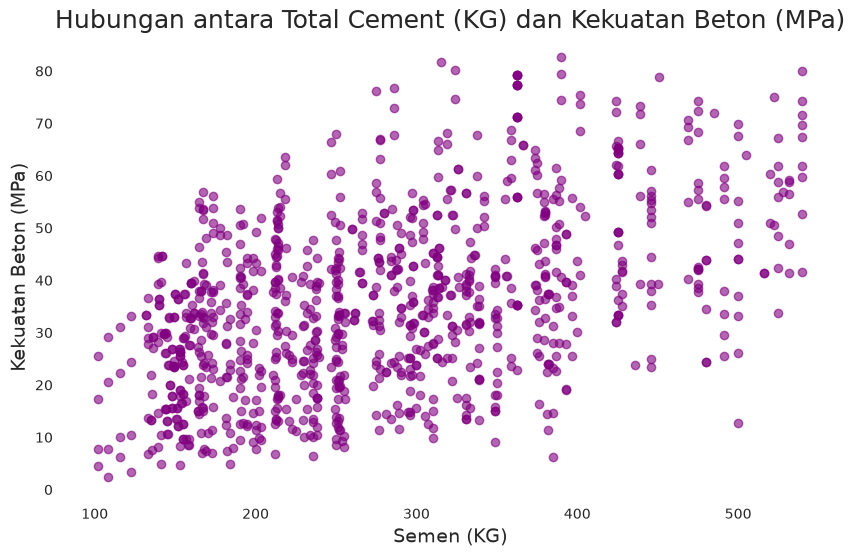

Korelasi Pearson antara cement dan strength = 0.4978


In [11]:
# Buat visualiasi scatter plot pada kolom "Cement" & "Strength"
sns.set({'figure.figsize': (10, 6)}, rc={'axes.facecolor': 'white'})
plt.scatter(x=data['cement'], y=data['strength'], color='purple', alpha=0.6)
plt.title('Hubungan antara Total Cement (KG) dan Kekuatan Beton (MPa)', size=18)
plt.xlabel('Semen (KG)', size=14)
plt.ylabel('Kekuatan Beton (MPa)', size=14)
plt.show()

print("Korelasi Pearson antara cement dan strength =",
      round(data['cement'].corr(data['strength']), 4))

### ii. Deskripsi

# Jelaskan hasil visualiasi scatter plot tersebut
Deskripsi scatter plot 'cement' vs 'strength':
1. Terdapat hubungan positif antara jumlah semen dan kekuatan beton, yaitu semakin besar
   jumlah semen (kg), semakin tinggi kekuatan tekan beton (MPa).
2. Nilai korelasi Pearson sebesar 0.4978 yang menunjukkan hubungan positif dengan
   kekuatan sedang (moderate), belum tergolong hubungan yang kuat.
3. Titik-titik data tersebar cukup lebar sehingga hubungan keduanya tidak sempurna / nonlinier.
   Artinya semen bukan satu-satunya faktor penentu kekuatan beton; variabel lain seperti umur (age),
   air, slag, ash, dan superplastic juga memengaruhi kekuatan tekan beton.

### iii. Uji Hipotesis
**Two sampled T-test**: <br>
Uji Independent Samples T Test atau 2-sample T-Test membandingkan rata-rata dua kelompok independen untuk menentukan apakah ada bukti statistik bahwa rata-rata populasi terkait berbeda secara signifikan.


Tentukan null dan alternate hypothesis. Secara umum, null hypothesis akan menyatakan bahwa kedua populasi yang diuji tidak memiliki perbedaan yang signifikan secara statistik. <br><br>
Alternate hypothesis akan menyatakan bahwa ada perbedaan.

    

In [12]:
# Buat uji hipotesis untuk menentukan null atau alternate hypothesis
# Two Sample T-Test: membandingkan rata-rata kekuatan beton dua kelompok independen
# yaitu campuran dengan semen rendah (<= median) dan semen tinggi (> median)

H0 = "Tidak ada perbedaan yang signifikan secara statistik antara rata-rata kekuatan beton\n     kelompok semen rendah dan kelompok semen tinggi"
H1 = "Terdapat perbedaan yang signifikan secara statistik antara rata-rata kekuatan beton\n     kelompok semen rendah dan kelompok semen tinggi"

median_cement = data['cement'].median()
kelompok_rendah = data[data['cement'] <= median_cement]['strength']
kelompok_tinggi = data[data['cement'] > median_cement]['strength']

print("H0 (null hypothesis)      :", H0)
print("H1 (alternate hypothesis) :", H1)
print()
print(f"Median cement             : {median_cement} kg")
print(f"Kelompok semen rendah     : n = {len(kelompok_rendah)}, rata-rata = {kelompok_rendah.mean():.2f} MPa, std = {kelompok_rendah.std():.2f} MPa")
print(f"Kelompok semen tinggi     : n = {len(kelompok_tinggi)}, rata-rata = {kelompok_tinggi.mean():.2f} MPa, std = {kelompok_tinggi.std():.2f} MPa")
print()

t_stat, p_value = ttest_ind(kelompok_rendah, kelompok_tinggi)
print("Two Sample T-Test (independent samples)")
print(f"t-statistic : {t_stat:.4f}")
print(f"p-value     : {p_value:.4e}")

alpha = 0.05
print(f" taraf signifikansi (alpha) = {alpha}")
if p_value < alpha:
    print(f" Keputusan : tolak H0 (p-value {p_value:.4e} < {alpha})")
else:
    print(f" Keputusan : gagal tolak H0 (p-value {p_value:.4e} >= {alpha})")

H0 (null hypothesis)      : Tidak ada perbedaan yang signifikan secara statistik antara rata-rata kekuatan beton
     kelompok semen rendah dan kelompok semen tinggi
H1 (alternate hypothesis) : Terdapat perbedaan yang signifikan secara statistik antara rata-rata kekuatan beton
     kelompok semen rendah dan kelompok semen tinggi

Median cement             : 272.9 kg
Kelompok semen rendah     : n = 515, rata-rata = 28.71 MPa, std = 13.33 MPa
Kelompok semen tinggi     : n = 515, rata-rata = 42.92 MPa, std = 16.73 MPa

Two Sample T-Test (independent samples)
t-statistic : -15.0792
p-value     : 1.4405e-46
 taraf signifikansi (alpha) = 0.05
 Keputusan : tolak H0 (p-value 1.4405e-46 < 0.05)


### iv. Kesimpulan akhir

# Berikan kesimpulan yang bisa di ambil dari analysis yg Anda lakukan
Kesimpulan analisis:
1. Univariate analysis kolom 'cement': distribusi jumlah semen pada 1030 data beton condong ke kanan
   (right-skewed), dengan rata-rata 281.17 kg, median 272.90 kg, standar deviasi 104.51 kg,
   serta rentang 102 - 540 kg. Sebagian besar campuran menggunakan semen pada rentang menengah
   (145 - 365 kg), sedikit yang menggunakan semen sangat tinggi (> 450 kg).
2. Bivariate analysis kolom 'cement' dan 'strength': terdapat hubungan positif sedang (r = 0.4978),
   yaitu bertambahnya jumlah semen cenderung diikuti bertambahnya kekuatan tekan beton,
   namun sebaran data menunjukkan hubungan yang tidak sempurna / nonlinier.
3. Uji hipotesis (Two Sample T-Test) memperoleh p-value sebesar 1.4404e-46 yang jauh lebih kecil
   dari taraf signifikansi 0.05, sehingga H0 ditolak. Rata-rata kekuatan beton kelompok semen
   tinggi (42.92 MPa) secara statistik berbeda signifikan dan lebih tinggi dibandingkan
   kelompok semen rendah (28.71 MPa).
4. Secara keseluruhan, jumlah semen berpengaruh signifikan terhadap kekuatan tekan beton,
   namun karena korelasinya hanya sedang, kekuatan beton juga ditentukan oleh variabel lain
   seperti umur pengerasan (age) dan bahan campuran lainnya.

<div class="alert alert-warning">
<strong>Perhatian!</strong> Berikut merupakan cara konversi File IPYNB menjadi File PDF untuk melakukan pengumpulan tugas di Virtual Class.
    <a href="https://youtu.be/qXELXtnAK7c">[VIDEO]</a>
    </div>



---


Copyright © Pengelola MK Praktikum Unggulan (Praktikum DGX), Universitas Gunadarma


https://www.praktikum-hpc.gunadarma.ac.id/